<a href="https://colab.research.google.com/github/mohitt770/ML_LAB/blob/main/electrical_motor_fault_prediction_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Electrical Motor Fault Prediction using Machine Learning

**Dataset expected:** Kaggle Playground Series S3E17 / AI4I-style predictive maintenance `train.csv`.

This notebook predicts the `Machine failure` target (0 = no failure, 1 = failure) using machine type, air/process temperature, rotational speed, torque, tool wear, and other available sensor/failure-indicator columns.

> Note: the file shared in ChatGPT was an `.ipynb` analysis notebook, not the raw CSV dataset. In Colab, upload the actual `train.csv` downloaded from the dataset source. This notebook also supports uploading a CSV with the expected columns.

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Import libraries

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Upload your dataset CSV
Run the cell and select the actual `train.csv` file from your computer. Do not upload this `.ipynb` notebook as the dataset.

In [23]:
uploaded = files.upload()  # Select train.csv
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file uploaded. Download and upload the dataset's train.csv file.")
file_name = csv_files[0]
df = pd.read_csv(file_name)

# Make column names easier to work with while retaining original meaning
df.columns = [c.strip() for c in df.columns]
print("Loaded:", file_name)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())

Saving train.csv to train.csv
Loaded: train.csv
Dataset shape: (136429, 14)


,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


\nColumns: ['id', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 3. Check the dataset and target

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-nu

,missing_values
id,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


\nTarget distribution:


,count
Machine failure,
No failure (0),134281
Failure (1),2148


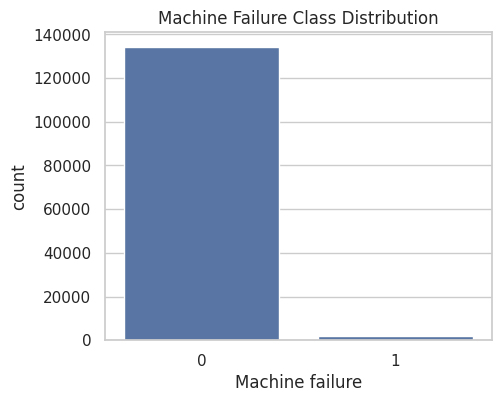

In [24]:
print("Dataset information:")
df.info()
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
print("\\nTarget distribution:")
if "Machine failure" not in df.columns:
    raise ValueError("Target column 'Machine failure' was not found. Please upload the labelled training CSV.")
display(df["Machine failure"].value_counts(dropna=False).rename(index={0: "No failure (0)", 1: "Failure (1)"}).to_frame("count"))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Class Distribution")
plt.show()

## 4. Prepare features and target
We remove identifiers because they generally do not describe machine condition. If the dataset contains `id` or `Product ID`, those columns are excluded. The target is `Machine failure`.

In [29]:
target = "Machine failure"
drop_candidates = [c for c in ["id", "ID", "Product ID"] if c in df.columns]
data = df.drop(columns=drop_candidates).copy()

# Convert target to numeric and remove rows without a target
data[target] = pd.to_numeric(data[target], errors="coerce")
data = data.dropna(subset=[target])
data[target] = data[target].astype(int)

X = data.drop(columns=[target])
y = data[target]

# Use stratification so both classes are represented in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Rows:", len(data))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Rows: 136429
Numeric features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Categorical features: ['Type']
Training rows: 109143 | Test rows: 27286


## 5. Train the Random Forest model
This is a practical baseline. Because failures are often much rarer than healthy cases, `class_weight='balanced'` can help the model pay more attention to the minority class.

In [30]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model training complete.")

Model training complete.


## 6. Evaluate the model
Do not rely on accuracy alone when failures are rare. Review failure-class precision, recall, F1 score, and the confusion matrix.

Accuracy : 0.9958
Precision: 0.9292
Recall   : 0.7930
F1 score : 0.8557
ROC-AUC  : 0.9573
\nClassification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     26856
           1       0.93      0.79      0.86       430

    accuracy                           1.00     27286
   macro avg       0.96      0.90      0.93     27286
weighted avg       1.00      1.00      1.00     27286



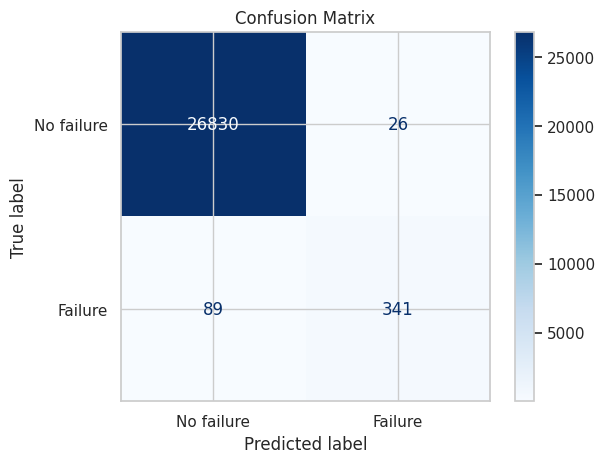

In [31]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
if y.nunique() == 2:
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No failure", "Failure"], cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

## 7. See example predictions

In [32]:
results = X_test.copy()
results["Actual failure"] = y_test
results["Predicted failure"] = y_pred
results["Predicted failure probability"] = y_prob
display(results.head(15))

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Actual failure,Predicted failure,Predicted failure probability
108143,L,303.3,311.2,1619,31.1,219,0,0,0,0,0,0,0,0.031052
124027,L,298.5,309.8,1663,36.1,203,0,0,0,0,0,0,0,0.025496
40415,M,297.0,308.1,1548,38.2,0,0,0,0,0,0,0,0,0.002344
5055,L,298.0,309.5,1599,35.7,51,0,0,0,0,0,0,0,0.001728
75315,L,296.9,307.8,1567,35.0,121,0,0,0,0,0,0,0,0.000500
129023,L,300.6,311.4,1446,40.3,75,0,0,0,0,0,0,0,0.000397
3698,L,298.8,310.5,1544,46.4,207,0,0,0,0,0,0,0,0.063637
11129,L,300.5,310.5,1536,40.2,12,0,0,0,0,0,0,0,0.000810
131286,M,297.6,309.3,1474,46.2,24,0,0,0,0,0,0,0,0.005219
11521,L,298.2,307.6,1369,50.7,82,0,0,0,0,0,0,0,0.021502


## 8. Predict a new motor observation
This helper uses the exact input columns that were used for training. Enter realistic readings and categories from your data. Do not use invented values for real maintenance decisions.

In [33]:
def predict_motor_failure(readings: dict):
    """readings must contain the same feature names as X.columns."""
    sample = pd.DataFrame([readings])
    missing = [c for c in X.columns if c not in sample.columns]
    extra = [c for c in sample.columns if c not in X.columns]
    if missing:
        raise ValueError(f"Missing required feature(s): {missing}")
    if extra:
        print("Ignoring extra feature(s):", extra)
        sample = sample[X.columns]
    else:
        sample = sample[X.columns]

    prediction = int(model.predict(sample)[0])
    probability = float(model.predict_proba(sample)[0, 1])
    label = "FAILURE PREDICTED" if prediction == 1 else "NO FAILURE PREDICTED"
    return {"prediction": label, "failure_probability": round(probability, 4)}

print("Feature columns required:", X.columns.tolist())
print("Example usage (replace values with a real row from your dataset):")
example = X.iloc[0].to_dict()
print(predict_motor_failure(example))

Feature columns required: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Example usage (replace values with a real row from your dataset):
{'prediction': 'NO FAILURE PREDICTED', 'failure_probability': 0.0013}


## 9. Save the trained model
The saved pipeline includes preprocessing and the trained model, so the same transformations are applied when it is loaded again.

In [ ]:
model_path = "electrical_motor_fault_prediction_model.joblib"
joblib.dump(model, model_path)
print("Saved model to:", model_path)
files.download(model_path)

## Project limitations and report notes

- This model predicts the dataset's `Machine failure` label; it does not automatically identify the physical cause of a fault unless you train a separate model using fault-type labels.
- The notebook shared in the conversation describes the Kaggle Playground Series S3E17 predictive-maintenance data, which includes machine type, air/process temperature, rotational speed, torque, tool wear, and failure labels. It is not the same as the CWRU vibration-signal dataset.
- Report the metrics produced by your own Colab run. Do not claim 99.6% accuracy unless your own evaluation actually achieves it, and include recall/confusion matrix because the dataset may be imbalanced.
- This is an educational prototype, not a safety-certified industrial protection system.